<a href="https://colab.research.google.com/github/sylviadu2552/DATA4401---Project-3/blob/main/Project3_n_grams.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub
from pathlib import Path
import pandas as pd

# Download latest version
path = Path(kagglehub.dataset_download("zynicide/wine-reviews"))
INPUT_FILE = path / "winemag-data-130k-v2.csv"

print("Dataset directory:", path)
print("Path to dataset file:", INPUT_FILE)

wines = pd.read_csv(INPUT_FILE, index_col=0)

print("Dataset shape:", wines.shape)
display(wines.head())

Using Colab cache for faster access to the 'wine-reviews' dataset.
Dataset directory: /kaggle/input/wine-reviews
Path to dataset file: /kaggle/input/wine-reviews/winemag-data-130k-v2.csv
Dataset shape: (129971, 13)


,country,description,designation,points,price,province,region_1,region_2,taster_name,taster_twitter_handle,title,variety,winery
0,Italy,"Aromas include tropical fruit, broom, brimston...",Vulkà Bianco,87,NaN,Sicily & Sardinia,Etna,NaN,Kerin O’Keefe,@kerinokeefe,Nicosia 2013 Vulkà Bianco (Etna),White Blend,Nicosia
1,Portugal,"This is ripe and fruity, a wine that is smooth...",Avidagos,87,15.0,Douro,NaN,NaN,Roger Voss,@vossroger,Quinta dos Avidagos 2011 Avidagos Red (Douro),Portuguese Red,Quinta dos Avidagos
2,US,"Tart and snappy, the flavors of lime flesh and...",NaN,87,14.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Rainstorm 2013 Pinot Gris (Willamette Valley),Pinot Gris,Rainstorm
3,US,"Pineapple rind, lemon pith and orange blossom ...",Reserve Late Harvest,87,13.0,Michigan,Lake Michigan Shore,NaN,Alexander Peartree,NaN,St. Julian 2013 Reserve Late Harvest Riesling ...,Riesling,St. Julian
4,US,"Much like the regular bottling from 2012, this...",Vintner's Reserve Wild Child Block,87,65.0,Oregon,Willamette Valley,Willamette Valley,Paul Gregutt,@paulgwine,Sweet Cheeks 2012 Vintner's Reserve Wild Child...,Pinot Noir,Sweet Cheeks


In [2]:
data = wines[["taster_name", "description"]].dropna().copy()
data["description"] = data["description"].astype(str).str.strip()
data = data[data["description"] != ""]

# Normalize case and whitespace only for duplicate detection
data["_text_key"] = (
    data["description"]
    .str.casefold()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Exclude identical wording assigned to multiple reviewers
reviewer_count_per_text = data.groupby("_text_key")["taster_name"].transform("nunique")
data = data[reviewer_count_per_text == 1]

# Keep one instance of each review
data = data.drop_duplicates(subset="_text_key")

# Keep reviewers with at least 100 unique reviews
reviewer_counts = data["taster_name"].value_counts()
eligible_reviewers = reviewer_counts[reviewer_counts >= 250].index
data = data[data["taster_name"].isin(eligible_reviewers)].copy()

print("Reviewers included:", len(eligible_reviewers))
print("Unique reviews used:", len(data))
display(data["taster_name"].value_counts().rename("reviews"))

Reviewers included: 16
Unique reviews used: 94882


,reviews
taster_name,
Roger Voss,23558
Michael Schachner,14045
Kerin O’Keefe,9679
Paul Gregutt,8867
Virginie Boone,8707
Matt Kettmann,5729
Joe Czerwinski,4763
Sean P. Sullivan,4460
Anna Lee C. Iijima,4017


In [3]:
from sklearn.model_selection import train_test_split

# Hold out test data for the final evaluation
X_train, X_test, y_train, y_test = train_test_split(
    data["description"],
    data["taster_name"],
    test_size=0.2,
    random_state=42,
    stratify=data["taster_name"]
)

# Set aside validation data from the training split for early stopping
X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=43,
    stratify=y_train
)

print("Fit reviews:", len(X_fit_text))
print("Validation reviews:", len(X_val_text))
print("Test reviews:", len(X_test))

Fit reviews: 64519
Validation reviews: 11386
Test reviews: 18977


In [4]:
import re
from collections import Counter

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from torch import nn
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

function_words = [
    "a", "an", "the", "and", "or", "but", "if", "of", "to", "in",
    "on", "at", "by", "for", "with", "from", "as", "is", "are",
    "was", "were", "be", "it", "this", "that", "which", "very", "not"
]
punctuation_marks = [",", ".", ";", ":", "!", "?", "—", "-", "(", ")", '"']

word_pattern = re.compile(r"\b[\w']+\b")
sentence_pattern = re.compile(r"[.!?]+")
punctuation_pattern = re.compile(r'[,.;:!?—()"\-]')

def style_features(text):
    text = str(text)
    words = word_pattern.findall(text.casefold())
    word_counts = Counter(words)
    sentences = [
        sentence for sentence in sentence_pattern.split(text)
        if sentence.strip()
    ]
    punctuation_counts = Counter(punctuation_pattern.findall(text))

    word_count = max(len(words), 1)
    sentence_count = max(len(sentences), 1)

    if words:
        word_lengths = np.fromiter(
            (len(word) for word in words),
            dtype=np.float32
        )
        mean_word_length = float(word_lengths.mean())
        std_word_length = float(word_lengths.std())
    else:
        mean_word_length = 0.0
        std_word_length = 0.0

    features = [
        np.log1p(len(text)),
        np.log1p(len(words)),
        mean_word_length,
        std_word_length,
        sentence_count / word_count,
        word_count / sentence_count,
    ]

    features.extend(
        word_counts[word] / word_count
        for word in function_words
    )
    features.extend(
        punctuation_counts[mark] * 100 / word_count
        for mark in punctuation_marks
    )

    return features

def make_feature_matrices(train_text, *eval_texts):
    train_text = list(train_text)
    eval_texts = [list(texts) for texts in eval_texts]

    vectorizer = TfidfVectorizer(
        analyzer="char",
        ngram_range=(3, 5),
        min_df=10,
        max_features=20_000,
        lowercase=False,
        dtype=np.float32
    )

    train_char = vectorizer.fit_transform(train_text)
    eval_char = [
        vectorizer.transform(texts)
        for texts in eval_texts
    ]

    train_style_raw = np.asarray(
        [style_features(text) for text in train_text],
        dtype=np.float32
    )
    eval_style_raw = [
        np.asarray(
            [style_features(text) for text in texts],
            dtype=np.float32
        )
        for texts in eval_texts
    ]

    scaler = StandardScaler()
    train_style = scaler.fit_transform(train_style_raw).astype(
        np.float32, copy=False
    )
    eval_style = [
        scaler.transform(features).astype(np.float32, copy=False)
        for features in eval_style_raw
    ]

    train_features = hstack(
        [train_char, csr_matrix(train_style)],
        format="csr"
    ).astype(np.float32, copy=False)

    eval_features = [
        hstack([char, csr_matrix(style)], format="csr").astype(
            np.float32, copy=False
        )
        for char, style in zip(eval_char, eval_style)
    ]

    return (train_features, *eval_features)

def to_torch_csr(matrix):
    matrix = matrix.tocsr(copy=False).astype(np.float32, copy=False)

    crow_indices = torch.from_numpy(
        np.asarray(matrix.indptr, dtype=np.int64)
    ).to(device)
    col_indices = torch.from_numpy(
        np.asarray(matrix.indices, dtype=np.int64)
    ).to(device)
    values = torch.from_numpy(
        np.asarray(matrix.data, dtype=np.float32)
    ).to(device)

    return torch.sparse_csr_tensor(
        crow_indices,
        col_indices,
        values,
        size=matrix.shape,
        device=device
    )

class SparseLinearReviewer(nn.Module):
    def __init__(self, n_features, n_classes):
        super().__init__()
        self.weight = nn.Parameter(
            torch.empty(n_features, n_classes, device=device)
        )
        self.bias = nn.Parameter(torch.zeros(n_classes, device=device))
        nn.init.xavier_uniform_(self.weight)

    def forward(self, x):
        return torch.sparse.mm(x, self.weight) + self.bias

def soft_macro_f1(logits, targets):
    probabilities = torch.softmax(logits, dim=1)
    true_positives = (probabilities * targets).sum(dim=0)
    predicted_positives = probabilities.sum(dim=0)
    actual_positives = targets.sum(dim=0)

    reviewer_f1 = (
        2 * true_positives
        / (predicted_positives + actual_positives + 1e-8)
    )

    return reviewer_f1.mean()

Using: cuda


In [10]:
X_fit_text, X_val_text, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=43,
    stratify=y_train
)

X_fit_features, X_val_features, X_test_features = make_feature_matrices(
    X_fit_text,
    X_val_text,
    X_test
)

X_fit_torch = to_torch_csr(X_fit_features)
X_val_torch = to_torch_csr(X_val_features)
X_test_torch = to_torch_csr(X_test_features)

label_encoder = LabelEncoder().fit(y_fit)
n_classes = len(label_encoder.classes_)

y_fit_ids = label_encoder.transform(y_fit)
y_val_ids = label_encoder.transform(y_val)

y_fit_torch = torch.tensor(y_fit_ids, dtype=torch.long, device=device)
y_val_torch = torch.tensor(y_val_ids, dtype=torch.long, device=device)

fit_targets = F.one_hot(y_fit_torch, num_classes=n_classes).float()
val_targets = F.one_hot(y_val_torch, num_classes=n_classes).float()

torch.manual_seed(42)
model = SparseLinearReviewer(X_fit_features.shape[1], n_classes)
optimizer = torch.optim.Adam(model.parameters(), lr=0.03)

max_epochs = 750
patience = 20
min_improvement = 1e-4

best_val_f1 = -float("inf")
best_epoch = 0
epochs_without_improvement = 0
best_weights = None
best_bias = None

for epoch in range(1, max_epochs + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    fit_logits = model(X_fit_torch)
    loss = 1 - soft_macro_f1(fit_logits, fit_targets)
    loss.backward()
    optimizer.step()

    model.eval()
    with torch.no_grad():
        val_logits = model(X_val_torch)
        val_f1 = soft_macro_f1(val_logits, val_targets).item()

    if val_f1 > best_val_f1 + min_improvement:
        best_val_f1 = val_f1
        best_epoch = epoch
        best_weights = model.weight.detach().clone()
        best_bias = model.bias.detach().clone()
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 25 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"loss: {loss.item():.4f} | "
            f"validation soft macro-F1: {val_f1:.4f}"
        )

    if epochs_without_improvement >= patience:
        print(f"Stopping early at epoch {epoch}.")
        break

with torch.no_grad():
    model.weight.copy_(best_weights)
    model.bias.copy_(best_bias)

# Keep these names for your existing evaluation cell
weights = model.weight
bias = model.bias

print("Best epoch:", best_epoch)
print("Best validation soft macro-F1:", round(best_val_f1, 4))

Epoch 001 | loss: 0.9499 | validation soft macro-F1: 0.0973
Epoch 025 | loss: 0.0960 | validation soft macro-F1: 0.8747
Epoch 050 | loss: 0.0317 | validation soft macro-F1: 0.9234
Epoch 075 | loss: 0.0175 | validation soft macro-F1: 0.9328
Epoch 100 | loss: 0.0122 | validation soft macro-F1: 0.9366
Epoch 125 | loss: 0.0095 | validation soft macro-F1: 0.9386
Epoch 150 | loss: 0.0077 | validation soft macro-F1: 0.9413
Epoch 175 | loss: 0.0064 | validation soft macro-F1: 0.9425
Epoch 200 | loss: 0.0055 | validation soft macro-F1: 0.9434
Epoch 225 | loss: 0.0048 | validation soft macro-F1: 0.9446
Epoch 250 | loss: 0.0044 | validation soft macro-F1: 0.9455
Epoch 275 | loss: 0.0040 | validation soft macro-F1: 0.9460
Epoch 300 | loss: 0.0037 | validation soft macro-F1: 0.9466
Epoch 325 | loss: 0.0035 | validation soft macro-F1: 0.9472
Epoch 350 | loss: 0.0032 | validation soft macro-F1: 0.9478
Epoch 375 | loss: 0.0030 | validation soft macro-F1: 0.9480
Epoch 400 | loss: 0.0029 | validation so

In [27]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score
)

with torch.no_grad():
    test_logits = torch.sparse.mm(X_test_torch, weights) + bias
    predicted_ids = test_logits.argmax(dim=1).cpu().numpy()

predicted_reviewers = label_encoder.inverse_transform(predicted_ids)

# Per-reviewer metrics
report = pd.DataFrame(
    classification_report(
        y_test,
        predicted_reviewers,
        output_dict=True,
        zero_division=0
    )
).T

by_reviewer = report.drop(
    index=["accuracy", "macro avg", "weighted avg"],
    errors="ignore"
).copy()

# Accuracy and weighted F1 are overall metrics, so leave them blank for individual reviewers
by_reviewer["accuracy"] = np.nan
by_reviewer["weighted_f1"] = np.nan

# Add one Overall row
overall = pd.DataFrame(
    [{
        "precision": report.loc["macro avg", "precision"],
        "recall": report.loc["macro avg", "recall"],
        "f1-score": f1_score(y_test, predicted_reviewers, average="macro"),
        "support": len(y_test),
        "accuracy": accuracy_score(y_test, predicted_reviewers),
        "weighted_f1": f1_score(y_test, predicted_reviewers, average="weighted")
    }],
    index=["Overall"]
)

results = pd.concat([
    by_reviewer.sort_values("f1-score", ascending=False),
    overall
])

display(
    results[
        ["precision", "recall", "f1-score"]
    ].round(3)
)

,precision,recall,f1-score
Kerin O’Keefe,0.994,0.995,0.994
Roger Voss,0.991,0.996,0.994
Michael Schachner,0.985,0.988,0.987
Matt Kettmann,0.990,0.979,0.985
Sean P. Sullivan,0.982,0.987,0.984
Anna Lee C. Iijima,0.985,0.983,0.984
Anne Krebiehl MW,0.989,0.976,0.982
Jim Gordon,0.977,0.971,0.974
Susan Kostrzewa,1.000,0.941,0.970
Lauren Buzzeo,0.985,0.953,0.969


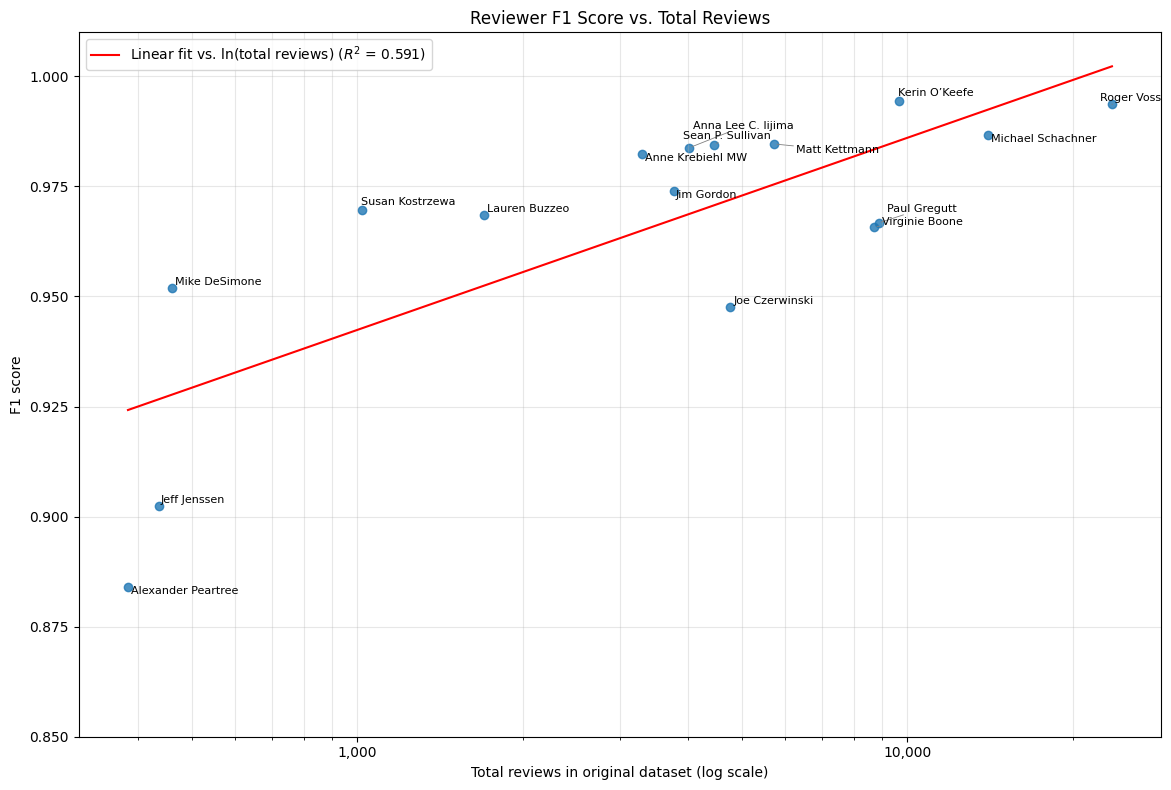

In [26]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import LogLocator, FuncFormatter
from adjustText import adjust_text

reviewer_counts = data["taster_name"].value_counts(dropna=True)

plot_data = by_reviewer.dropna(subset=["f1-score"]).copy()
plot_data["total_reviews"] = plot_data.index.map(reviewer_counts)
plot_data = plot_data[plot_data["total_reviews"] >= 250].copy()

# Fit a line against ln(total reviews)
x_log = np.log(plot_data["total_reviews"])
y_actual = plot_data["f1-score"]

slope, intercept = np.polyfit(x_log, y_actual, 1)
y_predicted = slope * x_log + intercept

ss_res = np.sum((y_actual - y_predicted) ** 2)
ss_tot = np.sum((y_actual - y_actual.mean()) ** 2)
r_squared = 1 - (ss_res / ss_tot)

x_line = np.geomspace(
    plot_data["total_reviews"].min(),
    plot_data["total_reviews"].max(),
    100
)
y_line = slope * np.log(x_line) + intercept

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    plot_data["total_reviews"],
    plot_data["f1-score"],
    alpha=0.8
)
ax.plot(
    x_line,
    y_line,
    color="red",
    label=f"Linear fit vs. ln(total reviews) ($R^2$ = {r_squared:.3f})"
)

# Add reviewer labels; adjust_text will reposition them to reduce overlap
texts = [
    ax.text(row["total_reviews"], row["f1-score"], str(reviewer), fontsize=8)
    for reviewer, row in plot_data.iterrows()
]

ax.set_xscale("log", base=10)
ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0,)))
ax.xaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:,.0f}")
)

ax.set_ylim(0.85, 1.01)
ax.set_yticks(np.arange(0.85, 1.001, 0.025))

ax.set_xlabel("Total reviews in original dataset (log scale)")
ax.set_ylabel("F1 score")
ax.set_title("Reviewer F1 Score vs. Total Reviews")
ax.grid(True, which="both", alpha=0.3)
legend = ax.legend()

plt.tight_layout()

# Run after setting up the plot so label placement uses the final axes
adjust_text(
    texts,
    x=plot_data["total_reviews"].to_numpy(),
    y=plot_data["f1-score"].to_numpy(),
    objects=[legend],
    ax=ax,
    arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.6},
    time_lim=2
)

plt.show()

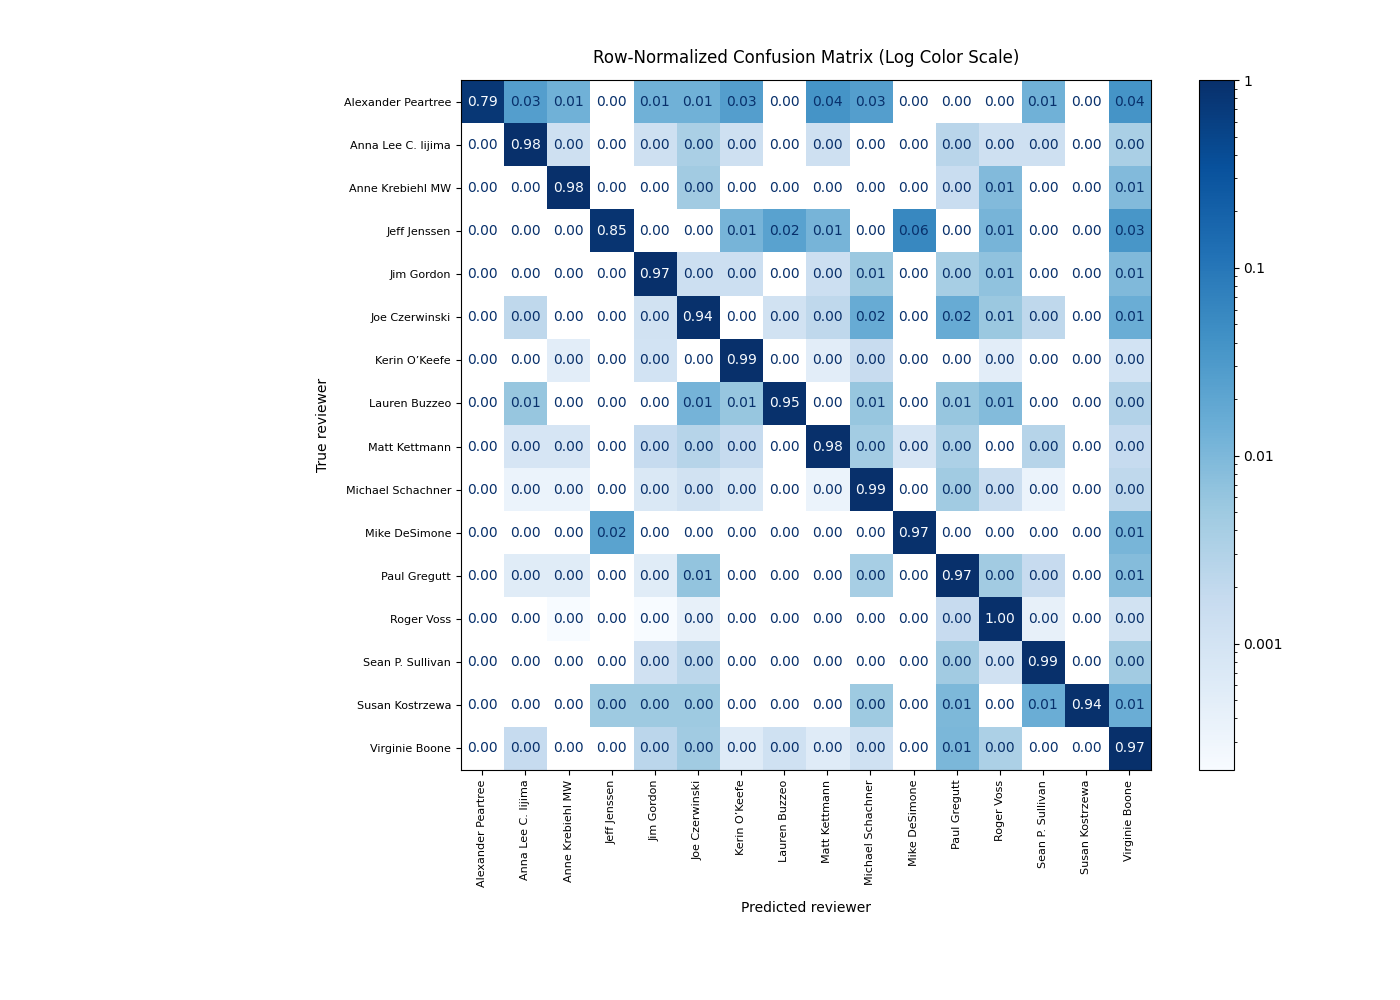

In [53]:
import io
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from IPython.display import Image, display
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from matplotlib.ticker import FuncFormatter

plt.ioff()

labels = label_encoder.classes_

# Calculate the row-normalized confusion matrix
cm = confusion_matrix(
    y_test,
    predicted_reviewers,
    labels=labels,
    normalize="true"
)

# Use the smallest nonzero value as the lower limit of the log scale
positive_values = cm[cm > 0]
vmin = positive_values.min()

fig, ax = plt.subplots(figsize=(14, 10), dpi=100)

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
)

display_matrix.plot(
    include_values=True,
    values_format=".2f",
    cmap="Blues",
    xticks_rotation=90,
    ax=ax,
    im_kw={"norm": LogNorm(vmin=vmin, vmax=1.0)}
)

colorbar = ax.images[0].colorbar
colorbar.ax.yaxis.set_major_formatter(
    FuncFormatter(lambda value, position: f"{value:g}")
)

ax.set_title("Row-Normalized Confusion Matrix (Log Color Scale)", pad=12)
ax.set_xlabel("Predicted reviewer", labelpad=10)
ax.set_ylabel("True reviewer", labelpad=10)
ax.tick_params(axis="both", labelsize=8)

fig.subplots_adjust(
    left=0.27,
    right=0.96,
    bottom=0.23,
    top=0.92
)

image_buffer = io.BytesIO()
fig.savefig(image_buffer, format="png", dpi=100)
plt.close(fig)

display(Image(data=image_buffer.getvalue(), width=1100))

In [36]:
import pandas as pd
from sklearn.metrics import (
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

# Per-reviewer test-set metrics
report = pd.DataFrame(
    classification_report(
        y_test,
        predicted_reviewers,
        output_dict=True,
        zero_division=0
    )
).T

reviewer_table = report.drop(
    index=["accuracy", "macro avg", "weighted avg"],
    errors="ignore"
)[["precision", "recall", "f1-score"]].copy()

reviewer_table.columns = ["Precision", "Recall", "F1-score"]

# Use counts from the original dataset
reviewer_counts = data["taster_name"].value_counts(dropna=True)
reviewer_table["Review count"] = (
    reviewer_table.index.map(reviewer_counts).fillna(0).astype(int)
)

reviewer_table = reviewer_table.sort_values("F1-score", ascending=False)

# Macro-averaged test-set metrics and total original-data review count
overall_row = pd.DataFrame(
    [{
        "Precision": precision_score(
            y_test, predicted_reviewers, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicted_reviewers, average="macro", zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicted_reviewers, average="macro", zero_division=0
        ),
        "Review count": reviewer_table["Review count"].sum()
    }],
    index=["Overall"]
)

results_table = pd.concat([reviewer_table, overall_row])
results_table.index.name = "Reviewer"

styled_table = (
    results_table.style
    .format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1-score": "{:.3f}",
        "Review count": "{:,.0f}"
    })
    .background_gradient(subset=["F1-score"], cmap="YlGn")
    .set_properties(**{"text-align": "center"})
    .set_table_styles([
        {"selector": "th", "props": [
            ("background-color", "#2F5597"),
            ("color", "white"),
            ("font-weight", "bold"),
            ("text-align", "center")
        ]},
        {"selector": "caption", "props": [
            ("caption-side", "top"),
            ("font-size", "16px"),
            ("font-weight", "bold")
        ]}
    ])
    .set_caption("Reviewer Classification Results")
)

display(styled_table)

,Precision,Recall,F1-score,Review count
Reviewer,,,,
Kerin O’Keefe,0.994,0.995,0.994,"9,679"
Roger Voss,0.991,0.996,0.994,"23,558"
Michael Schachner,0.985,0.988,0.987,"14,045"
Matt Kettmann,0.990,0.979,0.985,"5,729"
Sean P. Sullivan,0.982,0.987,0.984,"4,460"
Anna Lee C. Iijima,0.985,0.983,0.984,"4,017"
Anne Krebiehl MW,0.989,0.976,0.982,"3,289"
Jim Gordon,0.977,0.971,0.974,"3,766"
Susan Kostrzewa,1.000,0.941,0.970,"1,022"


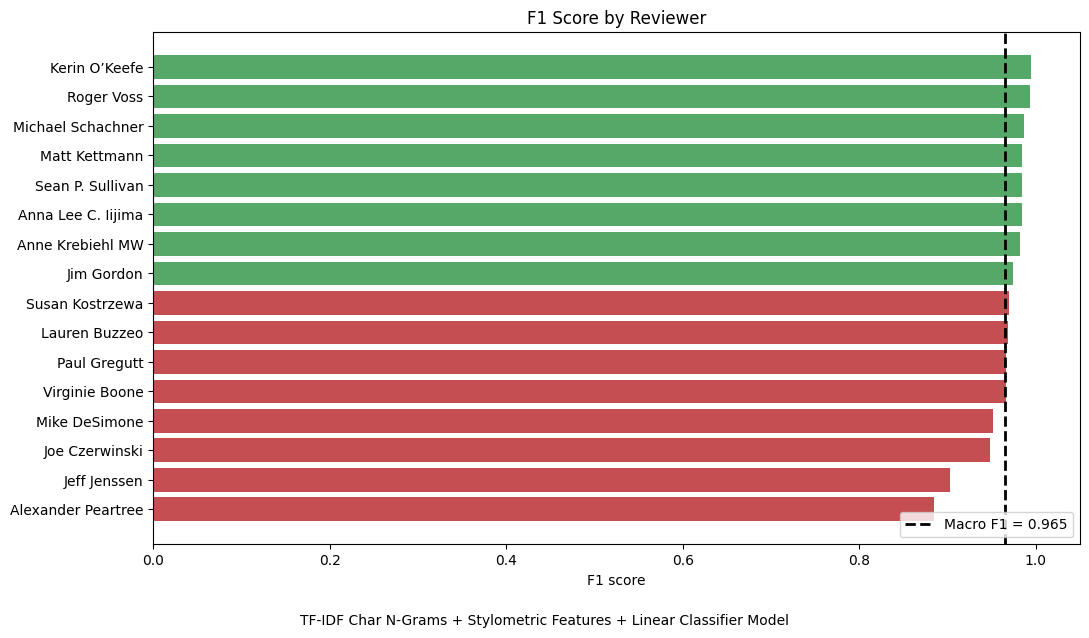

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Sort low-to-high so the highest F1 bars appear at the top
plot_data = reviewer_table.sort_values("F1-score", ascending=True)

n_reviewers = len(plot_data)
top_half_size = (n_reviewers + 1) // 2

# Red for the bottom half; green for the top half
bar_colors = ["#c44e52"] * n_reviewers
for i in range(n_reviewers - top_half_size, n_reviewers):
    bar_colors[i] = "#55a868"

# Macro F1 gives each reviewer equal weight
macro_avg_f1 = f1_score(
    y_test,
    predicted_reviewers,
    average="macro",
    zero_division=0
)

fig_height = max(6, 0.4 * n_reviewers)
fig, ax = plt.subplots(figsize=(11, fig_height))

ax.barh(
    plot_data.index.astype(str),
    plot_data["F1-score"],
    color=bar_colors
)

ax.axvline(
    macro_avg_f1,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"Macro F1 = {macro_avg_f1:.3f}"
)

ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 score")
ax.set_ylabel("")
ax.set_title("F1 Score by Reviewer")
ax.legend(loc="lower right", frameon=True)

# Leave room for the model name beneath the chart
fig.text(
    0.5,
    0.015,
    "TF-IDF Char N-Grams + Stylometric Features + Linear Classifier Model",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()